# WPTG 2026-2027 – Testy systemu transformacji grafów


In [1]:
import json
from wptg import Graph, Vertex, Production, Grammar, TransformationSystem

with open("graf_voronoi_ABCDE.json", "r", encoding="utf-8") as f:
    g_voronoi = Graph.from_dict(json.load(f))

with open("gramatyka_ABCDE.json", "r", encoding="utf-8") as f:
    gram = Grammar.from_dict(json.load(f))

print(f"Voronoi: {len(g_voronoi.vertices)} w., {len(g_voronoi.edges)} k. | ABCDE: {len(gram.productions)} produkcji")


Voronoi: 20 w., 50 k. | ABCDE: 15 produkcji


### 1. Graf Voronoia i produkcje P1, P6


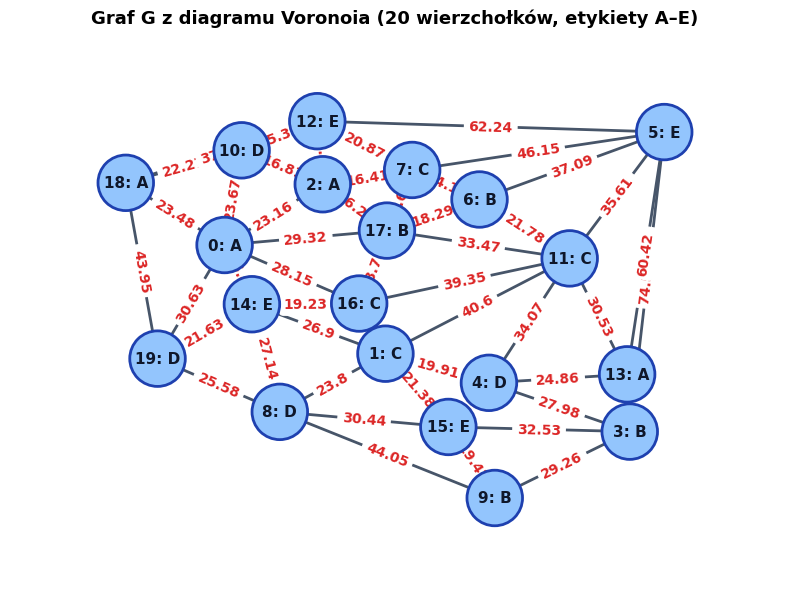

Wierzchołek,Etykieta,Stopień,Połączenia (Sąsiedzi)
0,A,7,"2 (A) [waga: 23.16], 10 (D) [waga: 23.67], 14 (E) [waga: 15.47], 16 (C) [waga: 28.15], 17 (B) [waga: 29.32], 18 (A) [waga: 23.48], 19 (D) [waga: 30.63]"
1,C,6,"4 (D) [waga: 19.91], 8 (D) [waga: 23.8], 11 (C) [waga: 40.6], 14 (E) [waga: 26.9], 15 (E) [waga: 21.38], 16 (C) [waga: 13.29]"
2,A,5,"0 (A) [waga: 23.16], 7 (C) [waga: 16.41], 10 (D) [waga: 16.81], 12 (E) [waga: 15.66], 17 (B) [waga: 16.26]"
3,B,5,"4 (D) [waga: 27.98], 5 (E) [waga: 74.51], 9 (B) [waga: 29.26], 13 (A) [waga: 14.21], 15 (E) [waga: 32.53]"
4,D,5,"1 (C) [waga: 19.91], 3 (B) [waga: 27.98], 11 (C) [waga: 34.07], 13 (A) [waga: 24.86], 15 (E) [waga: 13.14]"
5,E,6,"3 (B) [waga: 74.51], 6 (B) [waga: 37.09], 7 (C) [waga: 46.15], 11 (C) [waga: 35.61], 12 (E) [waga: 62.24], 13 (A) [waga: 60.42]"
6,B,4,"5 (E) [waga: 37.09], 7 (C) [waga: 14.12], 11 (C) [waga: 21.78], 17 (B) [waga: 18.29]"
7,C,5,"2 (A) [waga: 16.41], 5 (E) [waga: 46.15], 6 (B) [waga: 14.12], 12 (E) [waga: 20.87], 17 (B) [waga: 15.69]"
8,D,5,"1 (C) [waga: 23.8], 9 (B) [waga: 44.05], 14 (E) [waga: 27.14], 15 (E) [waga: 30.44], 19 (D) [waga: 25.58]"
9,B,3,"3 (B) [waga: 29.26], 8 (D) [waga: 44.05], 15 (E) [waga: 19.47]"


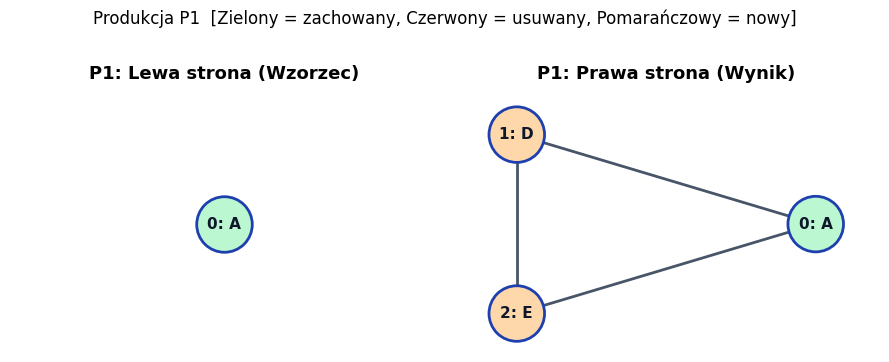

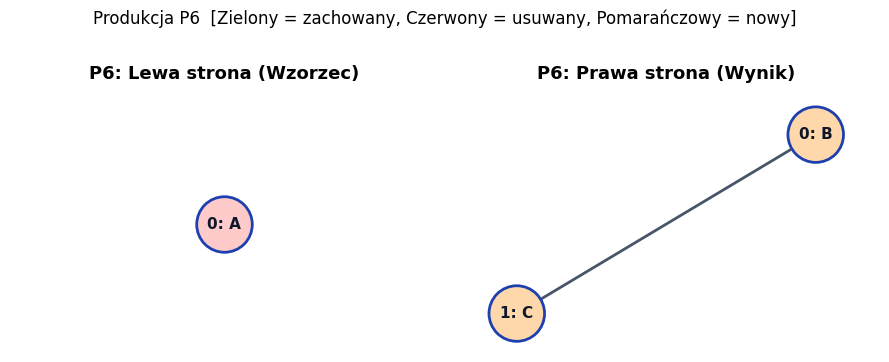

In [2]:
g_voronoi.visualize(figsize=(8, 6))
g_voronoi.display_table(mode="connections")
gram.get_production("P1").visualize(figsize=(9, 3.5))
gram.get_production("P6").visualize(figsize=(9, 3.5))


### 2. Wyprowadzenie siatki i tabele (połączenia, macierz, krawędzie)


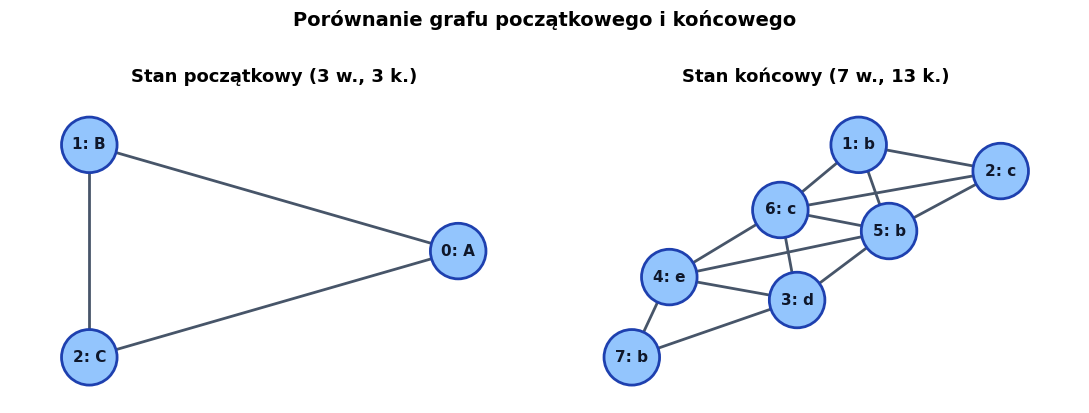

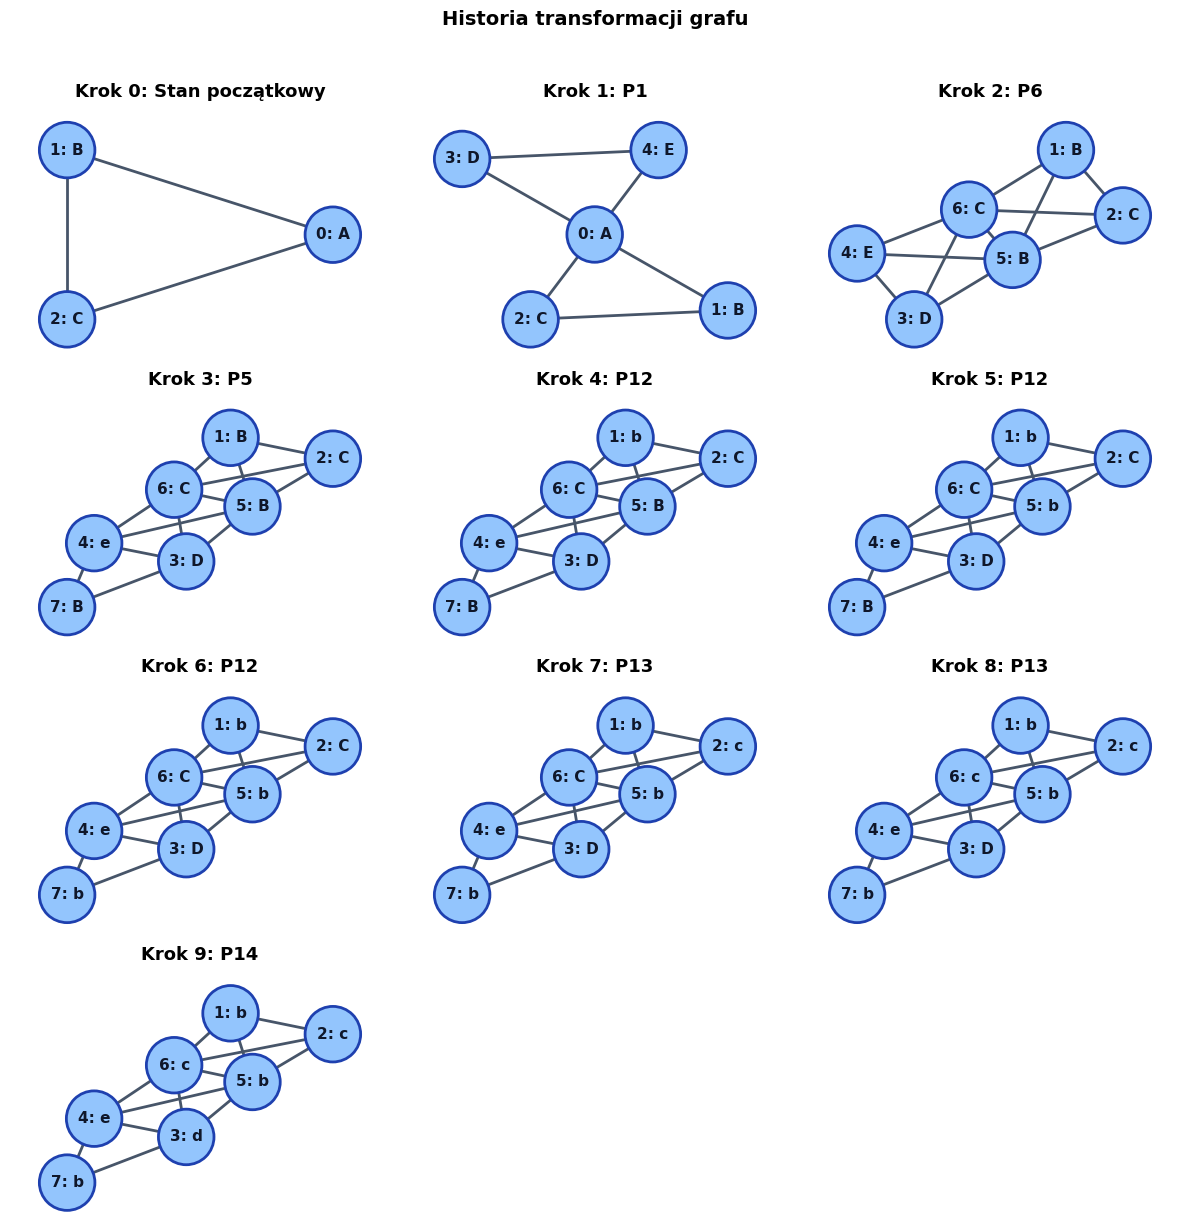

Wierzchołek,Etykieta,Stopień,Połączenia (Sąsiedzi)
0,A,2,"1 (B), 2 (C)"
1,B,2,"0 (A), 2 (C)"
2,C,2,"1 (B), 0 (A)"
Wierzchołek,Etykieta,Stopień,Połączenia (Sąsiedzi)
1,b,3,"2 (c), 5 (b), 6 (c)"
2,c,3,"1 (b), 5 (b), 6 (c)"
3,d,4,"4 (e), 5 (b), 6 (c), 7 (b)"
4,e,4,"3 (d), 5 (b), 6 (c), 7 (b)"
5,b,5,"6 (c), 1 (b), 2 (c), 3 (d), 4 (e)"
6,c,5,"5 (b), 1 (b), 2 (c), 3 (d), 4 (e)"


Wierzchołek,1:b,2:c,3:d,4:e,5:b,6:c,7:b
1:b,-,1,0,0,1,1,0
2:c,1,-,0,0,1,1,0
3:d,0,0,-,1,1,1,1
4:e,0,0,1,-,1,1,1
5:b,1,1,1,1,-,1,0
6:c,1,1,1,1,1,-,0
7:b,0,0,1,1,0,0,-


+--------+--------+--------------+--------------+-------------------+------+
| Od (u) | Do (v) | Etykieta (u) | Etykieta (v) | Etykieta krawędzi | Waga |
+--------+--------+--------------+--------------+-------------------+------+
| 1      | 2      | b            | c            | -                 | -    |
| 3      | 4      | d            | e            | -                 | -    |
| 5      | 6      | b            | c            | -                 | -    |
| 1      | 5      | b            | b            | -                 | -    |
| 1      | 6      | b            | c            | -                 | -    |
| 2      | 5      | c            | b            | -                 | -    |
| 2      | 6      | c            | c            | -                 | -    |
| 3      | 5      | d            | b            | -                 | -    |
| 3      | 6      | d            | c            | -                 | -    |
| 4      | 5      | e            | b            | -                 | -    |

In [3]:
ts_mesh = TransformationSystem(G=gram.start_graph.copy(), T=gram)
ts_mesh.apply(["P1", "P6", "P5"], selection_strategy=2, dangling_edges_handling=1)
ts_mesh.apply(["P11", "P12", "P13", "P14", "P15"], selection_strategy=1, dangling_edges_handling=1)

ts_mesh.visualize_initial_and_final(figsize=(11, 4))
ts_mesh.visualize_history(figsize_per_step=(4, 3), include_initial=True)
ts_mesh.display_initial_and_final_tables(mode="connections")
ts_mesh.G.display_table(mode="matrix")
ts_mesh.G.print_table(mode="edges")


### 3. Strategie selekcji na grafie Voronoia (Strategia 2 vs Strategia 1)


Po P6 (Strategia 2): 21 w., 58 k.


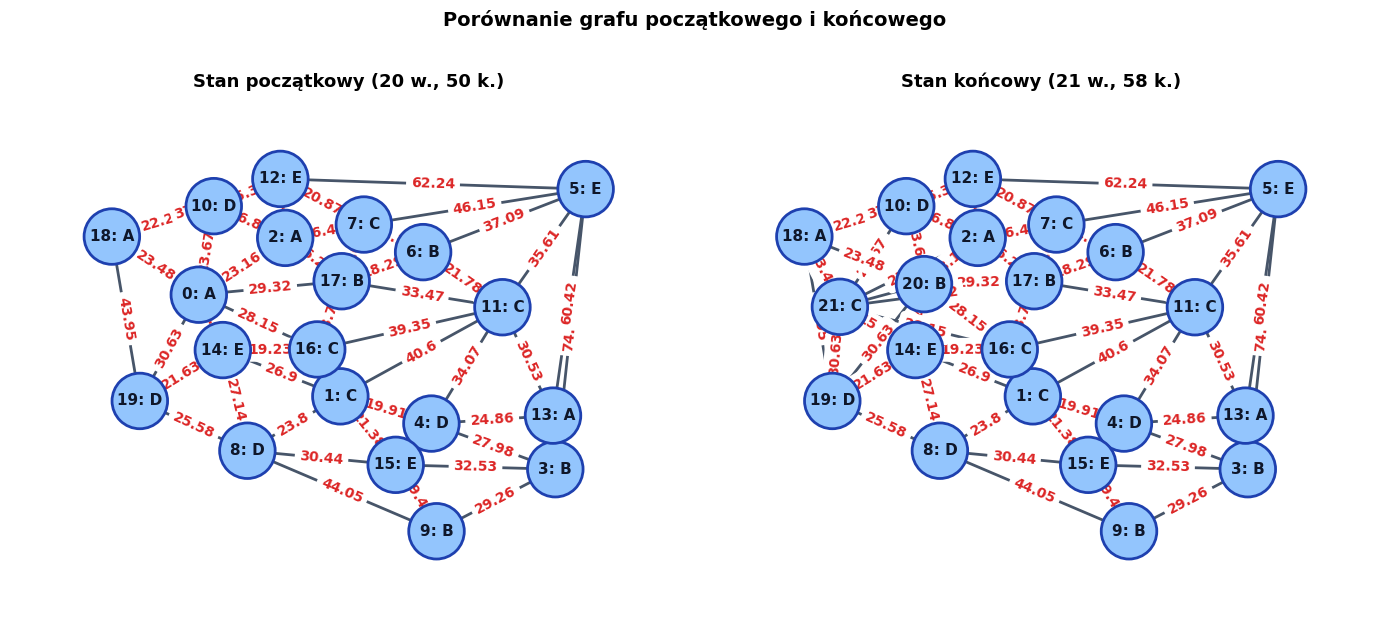

Po P11 (Strategia 1): 3 kroki, terminale 'a'=[2, 13, 18]


In [4]:
ts_s2 = TransformationSystem(G=g_voronoi.copy(), T=gram)
ts_s2.apply(["P6"], selection_strategy=2, dangling_edges_handling=1)
print(f"Po P6 (Strategia 2): {len(ts_s2.G.vertices)} w., {len(ts_s2.G.edges)} k.")
ts_s2.visualize_initial_and_final(figsize=(14, 6))

ts_s1 = TransformationSystem(G=ts_s2.G.copy(), T=gram)
applied_s1 = ts_s1.apply(["P11"], selection_strategy=1, dangling_edges_handling=1)
print(f"Po P11 (Strategia 1): {len(applied_s1)} kroki, terminale 'a'={[v.index for v in ts_s1.G.vertices if v.label == 'a']}")


### 4. Wiszące krawędzie: CANCEL (1) vs DELETE (2)


In [5]:
P_del_C = Production(
    name="P_del_C",
    left=Graph(vertices=[Vertex(0, "C")]),
    right=Graph(vertices=[Vertex(0, "c_iso")]),
    mapping=[],
    embedding=[]
)

ts_cancel = TransformationSystem(G=g_voronoi.copy(), T=gram)
res_cancel = ts_cancel.apply([P_del_C], selection_strategy=2, dangling_edges_handling=1)
print(f"CANCEL (1): kroki={len(res_cancel)}, krawędzie={len(ts_cancel.G.edges)}")

ts_delete = TransformationSystem(G=g_voronoi.copy(), T=gram)
res_delete = ts_delete.apply([P_del_C], selection_strategy=2, dangling_edges_handling=2)
print(f"DELETE (2): kroki={len(res_delete)}, krawędzie={len(ts_delete.G.edges)}")


CANCEL (1): kroki=0, krawędzie=50
DELETE (2): kroki=1, krawędzie=44


### 5. Wyświetlenie `siatki_graf.json` i `trojkaty.json` oraz interpretacja grafowa


siatki_graf.json: 6 w., 9 k.
trojkaty.json: nieterminale=['X', 'Y', 'Z'], terminale=['a', 'b', 'c'], produkcje=7


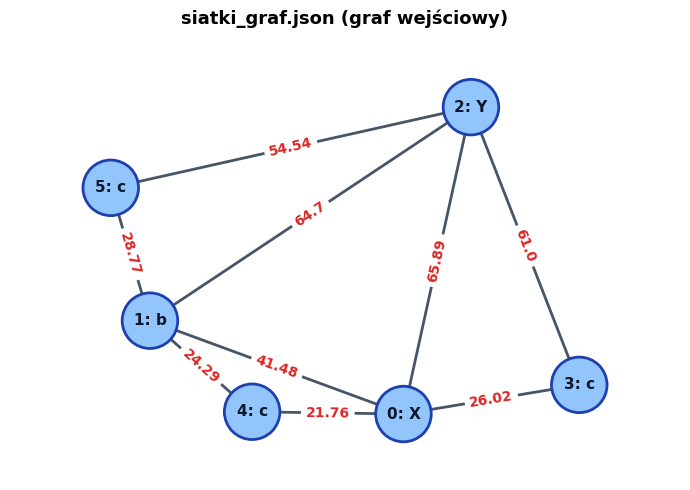

Wierzchołek,Etykieta,Stopień,Połączenia (Sąsiedzi)
0,X,4,"1 (b) [waga: 41.48], 2 (Y) [waga: 65.89], 3 (c) [waga: 26.02], 4 (c) [waga: 21.76]"
1,b,4,"0 (X) [waga: 41.48], 2 (Y) [waga: 64.7], 4 (c) [waga: 24.29], 5 (c) [waga: 28.77]"
2,Y,4,"0 (X) [waga: 65.89], 1 (b) [waga: 64.7], 3 (c) [waga: 61.0], 5 (c) [waga: 54.54]"
3,c,2,"0 (X) [waga: 26.02], 2 (Y) [waga: 61.0]"
4,c,2,"0 (X) [waga: 21.76], 1 (b) [waga: 24.29]"
5,c,2,"1 (b) [waga: 28.77], 2 (Y) [waga: 54.54]"


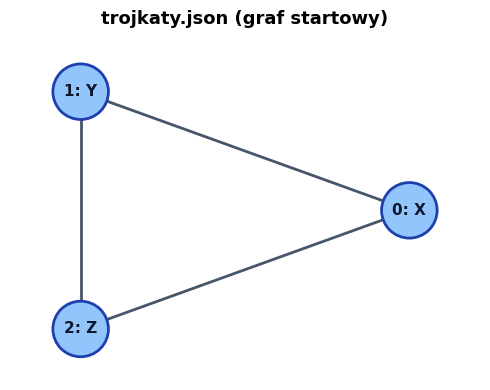

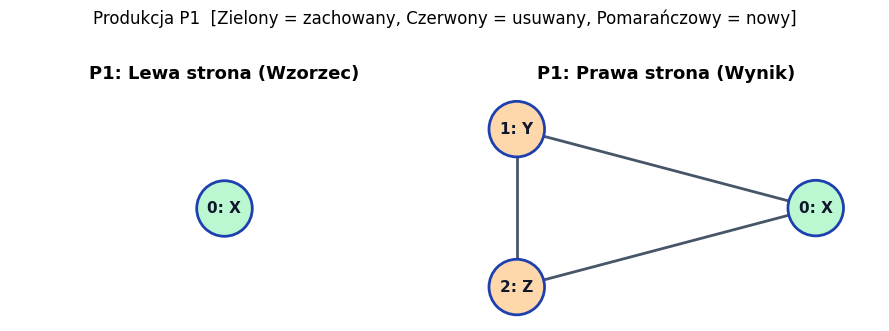

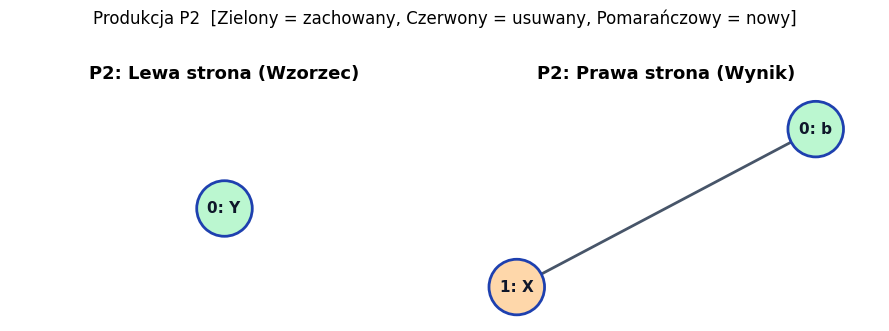

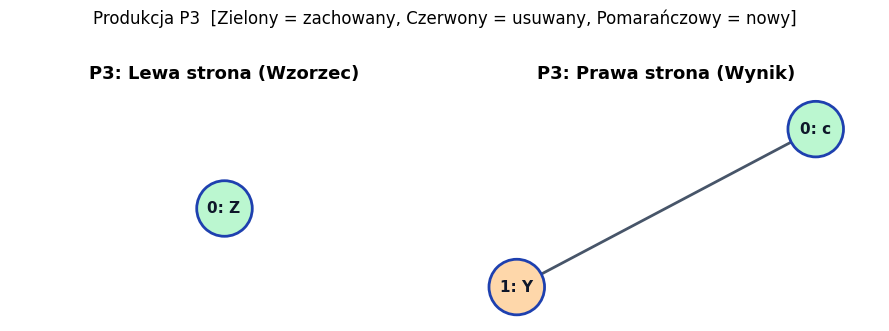

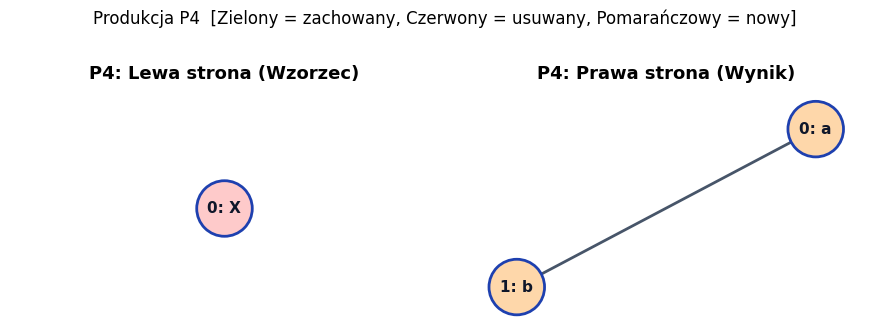

Krok 1 [P1]: [0:X, 1:b, 2:Y, 3:c, 4:c, 5:c, 6:Y, 7:Z] | krawędzie=12
Krok 2 [P3]: [0:X, 1:b, 2:Y, 3:c, 4:c, 5:c, 6:Y, 7:c, 8:Y] | krawędzie=14
Krok 3 [P4]: [1:b, 2:Y, 3:c, 4:c, 5:c, 6:Y, 7:c, 8:Y, 9:a, 10:b] | krawędzie=22
Krok 4 [P6]: [1:b, 2:b, 3:c, 4:c, 5:c, 6:Y, 7:c, 8:Y, 9:a, 10:b] | krawędzie=22
Krok 5 [P6]: [1:b, 2:b, 3:c, 4:c, 5:c, 6:b, 7:c, 8:Y, 9:a, 10:b] | krawędzie=22
Krok 6 [P6]: [1:b, 2:b, 3:c, 4:c, 5:c, 6:b, 7:c, 8:b, 9:a, 10:b] | krawędzie=22


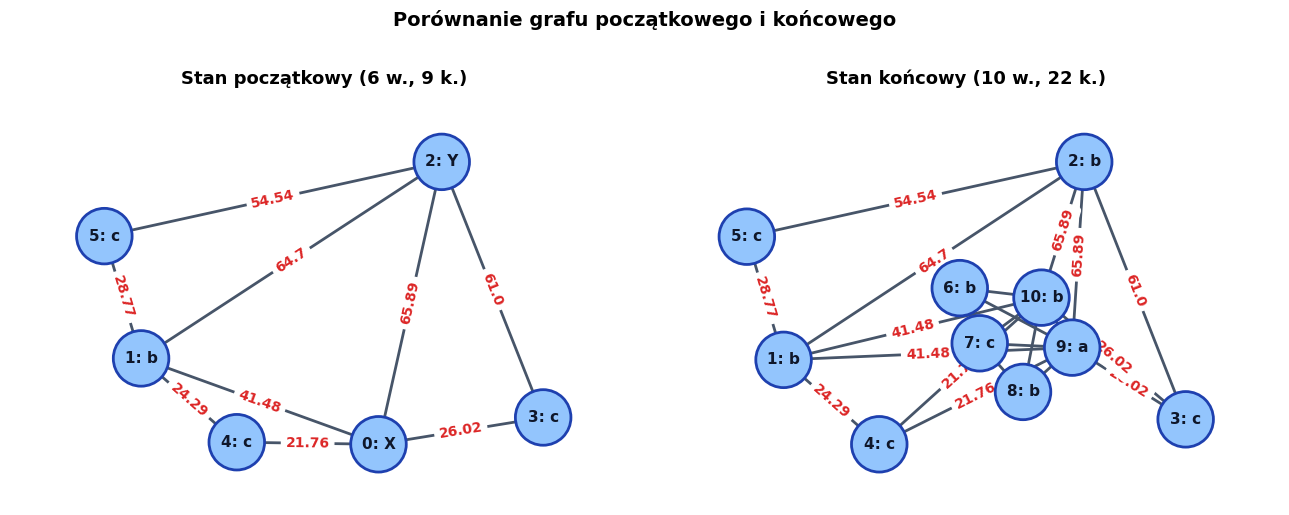

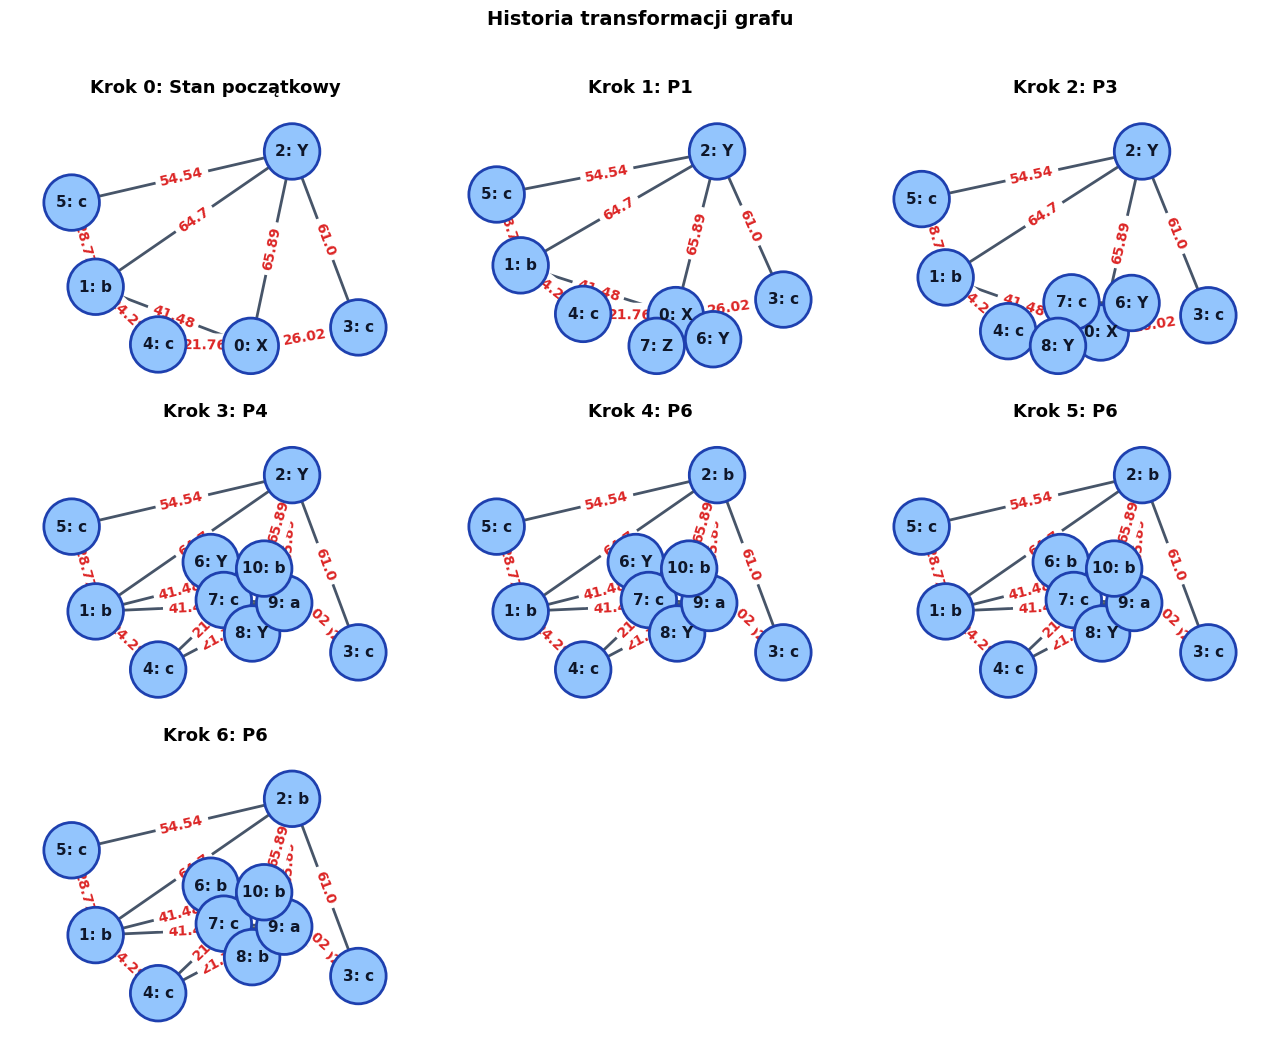

Wierzchołek,Etykieta,Stopień,Połączenia (Sąsiedzi)
0,X,4,"1 (b) [waga: 41.48], 2 (Y) [waga: 65.89], 3 (c) [waga: 26.02], 4 (c) [waga: 21.76]"
1,b,4,"0 (X) [waga: 41.48], 2 (Y) [waga: 64.7], 4 (c) [waga: 24.29], 5 (c) [waga: 28.77]"
2,Y,4,"0 (X) [waga: 65.89], 1 (b) [waga: 64.7], 3 (c) [waga: 61.0], 5 (c) [waga: 54.54]"
3,c,2,"0 (X) [waga: 26.02], 2 (Y) [waga: 61.0]"
4,c,2,"0 (X) [waga: 21.76], 1 (b) [waga: 24.29]"
5,c,2,"1 (b) [waga: 28.77], 2 (Y) [waga: 54.54]"
Wierzchołek,Etykieta,Stopień,Połączenia (Sąsiedzi)
1,b,5,"2 (b) [waga: 64.7], 4 (c) [waga: 24.29], 5 (c) [waga: 28.77], 9 (a) [waga: 41.48], 10 (b) [waga: 41.48]"
2,b,5,"1 (b) [waga: 64.7], 3 (c) [waga: 61.0], 5 (c) [waga: 54.54], 9 (a) [waga: 65.89], 10 (b) [waga: 65.89]"
3,c,3,"2 (b) [waga: 61.0], 9 (a) [waga: 26.02], 10 (b) [waga: 26.02]"


In [6]:
with open("siatki_graf.json", "r", encoding="utf-8") as f:
    g_siatki = Graph.from_dict(json.load(f))

with open("trojkaty.json", "r", encoding="utf-8") as f:
    gram_trojkaty = Grammar.from_dict(json.load(f))

print(f"siatki_graf.json: {len(g_siatki.vertices)} w., {len(g_siatki.edges)} k.")
print(f"trojkaty.json: nieterminale={gram_trojkaty.nonterminals}, terminale={gram_trojkaty.terminals}, produkcje={len(gram_trojkaty.productions)}")

g_siatki.visualize(title="siatki_graf.json (graf wejściowy)", figsize=(7, 5))
g_siatki.display_table(mode="connections")
gram_trojkaty.start_graph.visualize(title="trojkaty.json (graf startowy)", figsize=(5, 4))

for pname in ["P1", "P2", "P3", "P4"]:
    gram_trojkaty.get_production(pname).visualize(figsize=(9, 3.2))

ts_siatki = TransformationSystem(G=g_siatki.copy(), T=gram_trojkaty)
ts_siatki.apply(["P1", "P3", "P4"], selection_strategy=2, dangling_edges_handling=1)
ts_siatki.apply(["P5", "P6", "P7"], selection_strategy=1, dangling_edges_handling=1)

for i, (prod, g_step) in enumerate(ts_siatki.History):
    v_str = ", ".join(f"{v.index}:{v.label}" for v in g_step.vertices)
    print(f"Krok {i+1} [{prod.name}]: [{v_str}] | krawędzie={len(g_step.edges)}")

ts_siatki.visualize_initial_and_final(figsize=(13, 5))
ts_siatki.visualize_history(figsize_per_step=(4.3, 3.4), include_initial=True)
ts_siatki.display_initial_and_final_tables(mode="connections")


### 6. Własna kolejność produkcji


Produkcje: P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11, P12, P13, P14, P15
Sekwencja: P1 P2 P6 | kroki=3


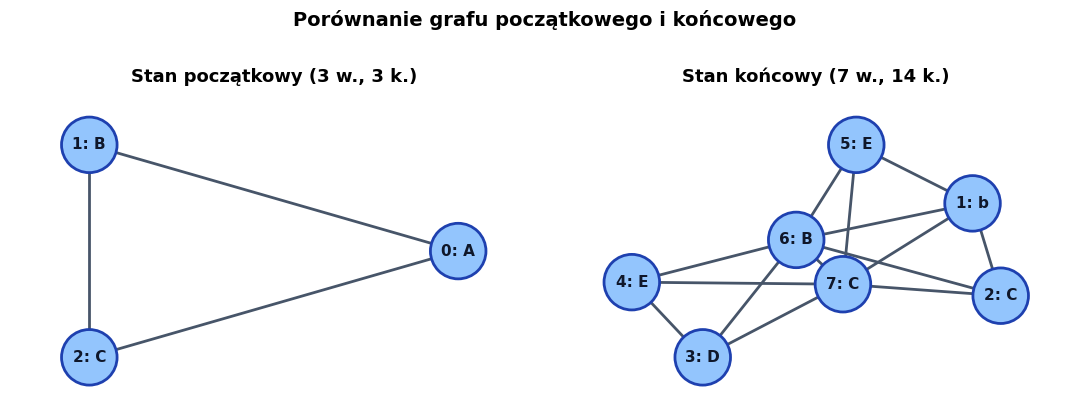

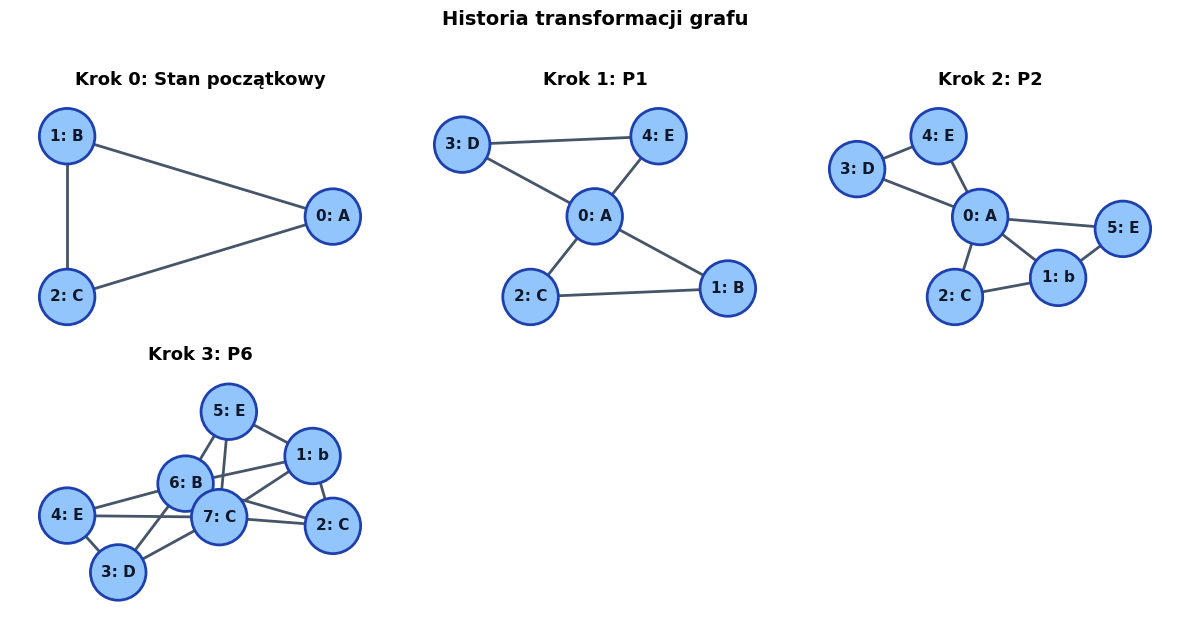

Wierzchołek,Etykieta,Stopień,Połączenia (Sąsiedzi)
0,A,4,"1 (B), 2 (C), 3 (D), 4 (E)"
1,B,2,"0 (A), 2 (C)"
2,C,2,"1 (B), 0 (A)"
3,D,2,"0 (A), 4 (E)"
4,E,2,"3 (D), 0 (A)"
Wierzchołek,Etykieta,Stopień,Połączenia (Sąsiedzi)
0,A,5,"1 (b), 2 (C), 3 (D), 4 (E), 5 (E)"
1,b,3,"0 (A), 2 (C), 5 (E)"
2,C,2,"1 (b), 0 (A)"
3,D,2,"0 (A), 4 (E)"


In [7]:
wybrany_graf = gram.start_graph.copy()
wybrana_gramatyka = gram
domyslna_sekwencja = "P1, P2, P6, P11"
strategia_selekcji = 2
obsluga_wiszacych = 1

print("Produkcje:", ", ".join(p.name for p in wybrana_gramatyka.productions))
try:
    wpisana = input(f"Kolejność produkcji (Enter = '{domyslna_sekwencja}'): ").strip()
except EOFError:
    wpisana = ""

sekwencja = wpisana if wpisana else domyslna_sekwencja
ts_custom = TransformationSystem(G=wybrany_graf, T=wybrana_gramatyka)
try:
    applied = ts_custom.apply(sekwencja, selection_strategy=strategia_selekcji, dangling_edges_handling=obsluga_wiszacych)
    print(f"Sekwencja: {sekwencja} | kroki={len(applied)}")
    ts_custom.visualize_initial_and_final(figsize=(11, 4))
    ts_custom.visualize_history(figsize_per_step=(4, 3), include_initial=True)
    ts_custom.display_history_tables(mode="connections")
except ValueError as err:
    print(f"Błąd: {err}")
